---
title: "Figures: The Lucas Asset Pricing Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=LucasAssetPrice.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/asset_pricing/LucasAssetPrice/LucasAssetPrice.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/asset_pricing/LucasAssetPrice/LucasAssetPrice.ipynb).

In [the Lucas model](https://intertemporal-choice.github.io/content/asset-pricing/lucasassetprice), consumption is the fruit of the trees, $c_{t} = d_{t}$, and with CRRA utility the price of a tree relative to its dividend satisfies

$$
\frac{\mathsf{P}_{t}}{d_{t}} = \beta\,\mathbb{E}_{t}\left[\left(\frac{d_{t+1}}{d_{t}}\right)^{1-\rho}\left(1+\frac{\mathsf{P}_{t+1}}{d_{t+1}}\right)\right], \qquad \beta = \frac{1}{1+\vartheta}.
$$

The log of the dividend, $x_{t} = \log d_{t}$, follows

$$
x_{t+1} = \tau x_{t} + \gamma + z_{t+1}, \qquad z_{t+1} \sim \mathcal{N}(-\sigma^{2}/2,\sigma^{2}),
$$

so dividends are IID when the persistence $\tau$ is zero and a random walk when it is one; in a random walk they grow by the factor $e^{\gamma}$ a period on average. The notebook computes the price-dividend ratio two ways, from the chapter's exact series and by solving the pricing equation itself; then the riskless rate and the expected return that go with it; how risk aversion moves prices, with and without growth; and the price of a second, small tree whose dividends move only partly with the economy's.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
from dataclasses import dataclass, replace

import numpy as np
from scipy.interpolate import CubicSpline

In [ ]:
import matplotlib.pyplot as plt

from intertemporal_choice import lucas, style

style.use_book_style()

## The economy

`Economy` holds the parameters. Its defaults are the chapter's: relative risk aversion $\rho = 3$, a time preference rate $\vartheta = 0.04$, $\sigma = 0.1$, IID dividends and no growth. `replace(e, tau=0.9)` is the same economy with persistence 0.9.

In [ ]:
@dataclass(frozen=True)
class Economy:
    rho: float = 3.0     # relative risk aversion
    theta: float = 0.04  # time preference rate
    sigma: float = 0.1   # standard deviation of the shock z to log dividends
    tau: float = 0.0     # persistence of log dividends: 0 for IID, 1 for a random walk
    gamma: float = 0.0   # growth: in a random walk, dividends grow by the factor e**gamma on average

    @property
    def beta(self):      # the time preference factor
        return 1 / (1 + self.theta)

## The exact series

The price is the value of every future dividend, each discounted by the stochastic discount factor, so the price-dividend ratio is $\sum_{n\geq 1}\beta^{n}\,\mathbb{E}_{t}[(d_{t+n}/d_{t})^{1-\rho}]$. Each term, a "strip", is the expectation of a lognormal variable. With $S_{n} = \sum_{k=0}^{n-1}\tau^{k}$ and $Q_{n} = \sum_{k=0}^{n-1}\tau^{2k}$,

$$
\mathbb{E}_{t}\left[\left(\frac{d_{t+n}}{d_{t}}\right)^{1-\rho}\right] = \exp\left((1-\rho)\big((\tau^{n}-1)x_{t} + \gamma S_{n}\big) - \frac{\sigma^{2}}{2}(1-\rho)S_{n} + \frac{\sigma^{2}}{2}(1-\rho)^{2}Q_{n}\right).
$$

`pd_series` adds the strips up. In a random walk, $\tau = 1$, each strip is the one before it times the same factor, so the sum is a geometric series, $y/(1-y)$ with $y = \beta\,\mathbb{E}_{t}[(d_{t+1}/d_{t})^{1-\rho}]$, finite only if $y < 1$. With $\tau < 1$ each strip settles at a constant as $n$ grows, so discounting by $\beta^{n}$ makes the sum finite.

In [ ]:
def log_strip(e, n, x):
    """The log of the value of the dividend n periods ahead relative to today's,
    log E_t[(d_{t+n}/d_t)**(1-rho)], when today's log dividend is x."""
    S = n if e.tau == 1 else (1 - e.tau**n) / (1 - e.tau)  # the sum of tau**k for k < n
    Q = n if e.tau == 1 else (1 - e.tau ** (2 * n)) / (1 - e.tau**2)  # the sum of tau**(2k)
    a = 1 - e.rho
    return a * ((e.tau**n - 1) * x + e.gamma * S) - e.sigma**2 / 2 * a * S + e.sigma**2 / 2 * a**2 * Q


def pd_series(e, d, horizon=100_000):
    """The price-dividend ratio of Lucas's tree when the dividend is d: the sum of beta**n times
    the strips (added in logs, since a strip alone can be too large for the computer)."""
    if e.tau == 1:  # a geometric series: y + y**2 + ... = y/(1-y), infinite unless y < 1
        y = np.exp(np.log(e.beta) + log_strip(e, 1, np.log(d)))
        return y / (1 - y) if y < 1 else np.inf
    n = np.arange(1, horizon + 1)
    with np.errstate(over="ignore"):
        terms = np.exp(n * np.log(e.beta) + log_strip(e, n, np.log(d)))
    if not terms[-1] < 1e-12 * terms.sum():
        raise ValueError(f"the series has not converged in {horizon:,} terms: raise the horizon")
    return terms.sum()

In [ ]:
e = Economy()
print(f"No risk:              {1 / e.theta:6.1f}")
print(f"IID dividends, d = 1: {pd_series(e, 1):6.1f}")
print(f"Random walk:          {pd_series(replace(e, tau=1), 1):6.1f}")

No risk:                25.0
IID dividends, d = 1:   25.8
Random walk:           108.0


## The numerical solution

The series needs lognormal shocks and a tree whose dividend is consumption. Solving the pricing equation itself needs neither. `solve` guesses the price-dividend ratio at each point of a grid of log dividends, uses the pricing equation to compute what today's ratio must be if tomorrow's is the guess, and repeats with the result as the new guess. The expectation over tomorrow's shock is a weighted average over fifteen values of it (Gauss-Hermite quadrature), and between grid points the log of the ratio is interpolated by a cubic spline. As long as a finite price exists, each round shrinks the error, so the guesses converge to the solution.

How the tree's dividend grows is an argument, `growth`. For Lucas's tree it is consumption's growth, $d_{t+1}/d_{t} = e^{x_{t+1}-x_{t}}$; the small tree at the end passes another. `solve` returns the ratio as a function of the dividend, which applies the pricing equation once more at whatever dividend it is given.

In [ ]:
z_std, weights = np.polynomial.hermite_e.hermegauss(15)  # values of a standard normal, and their
weights = weights / weights.sum()                       # probabilities, for the averages


def aggregate(e, x, x_next, own):
    """Lucas's tree: its dividend is consumption, so it grows as consumption does."""
    return np.exp(x_next - x)


def next_x(e, x):
    """Tomorrow's log dividend at each of the fifteen values of the shock z (the last axis)."""
    z = -e.sigma**2 / 2 + e.sigma * z_std
    return e.tau * np.asarray(x, float)[..., None] + e.gamma + z


def discounted_growth(e, growth, x):
    """Tomorrow's log dividend, and beta * (c_{t+1}/c_t)**(-rho) * d_{t+1}/d_t at each value of the
    shock, averaged over any shock of the tree's own (a second average, which changes nothing for
    Lucas's tree)."""
    x_next = next_x(e, x)
    x = np.asarray(x, float)[..., None]
    sdf = e.beta * np.exp(-e.rho * (x_next - x))
    own = sum(w * growth(e, x, x_next, s) for s, w in zip(z_std, weights))
    return x_next, sdf * own


def interpolate(grid, values, x):
    """values, given on the grid, at x: a cubic spline between grid points, and straight lines
    beyond the ends."""
    spline = CubicSpline(grid, values)
    inside = spline(np.clip(x, grid[0], grid[-1]))
    below = values[0] + spline(grid[0], 1) * (x - grid[0])     # spline(point, 1) is its slope there
    above = values[-1] + spline(grid[-1], 1) * (x - grid[-1])
    return np.where(x < grid[0], below, np.where(x > grid[-1], above, inside))


def solve(e, growth=aggregate, points=101, tolerance=1e-11):
    """The price-dividend ratio of a tree whose dividend grows by `growth`, as a function of the
    aggregate dividend: the fixed point of the pricing equation."""
    spread = e.sigma / np.sqrt(1 - e.tau**2) if e.tau < 1 else e.sigma    # the spread of x,
    center = (e.gamma - e.sigma**2 / 2) / (1 - e.tau) if e.tau < 1 else 0  # and its mean
    grid = center + spread * np.linspace(-6, 6, points)
    x_next, m = discounted_growth(e, growth, grid)

    ratio = m @ weights  # the first round, with tomorrow's ratio taken to be zero
    for _ in range(100_000):
        new = (m * (1 + np.exp(interpolate(grid, np.log(ratio), x_next)))) @ weights
        if not np.isfinite(new).all() or np.median(new) > 1e9:
            raise ValueError("the ratio grows without limit: there is no finite price")
        if np.max(np.abs(new / ratio - 1)) < tolerance:
            break
        ratio = new
    else:
        raise RuntimeError("the ratio has not converged in 100,000 rounds")

    def ratio_at(d):
        x_next, m = discounted_growth(e, growth, np.log(d))
        return (m * (1 + np.exp(interpolate(grid, np.log(new), x_next)))) @ weights

    return ratio_at

The two methods agree. These are the chapter's numbers for persistence: at the mean dividend, $d = 1$, more persistence raises the ratio, steeply as $\tau$ nears one, where the random walk's ratio is the limit; at $d = 2$ it first lowers it, because a dividend above its mean is expected to fall back, and more persistence slows the fall.

In [ ]:
print("    tau   d = 1: series  solved   d = 2: series  solved")
for tau in (0, 0.6, 0.9, 0.99, 0.999, 1):
    et = replace(e, tau=tau)
    ratio = solve(et)
    print(f"{tau:7}  {pd_series(et, 1):13.1f} {ratio(1):7.1f} {pd_series(et, 2):15.1f} {ratio(2):7.1f}")

    tau   d = 1: series  solved   d = 2: series  solved
      0           25.8    25.8           103.0   103.0
    0.6           26.4    26.4            99.4    99.4


    0.9           29.5    29.5            89.3    89.3
   0.99           47.6    47.6            73.2    73.2


  0.999           80.8    80.8            88.7    88.7


      1          108.0   108.0           108.0   108.0


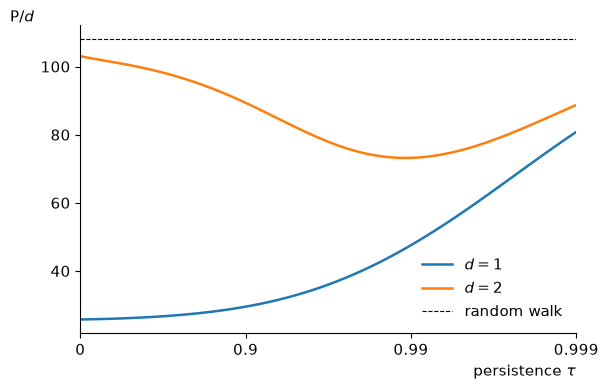

In [ ]:
k = np.linspace(0, 3, 61)  # tau = 1 - 10**(-k), from 0 to 0.999
ratios = {f"$d = {d}$": [pd_series(replace(e, tau=t), d) for t in lucas.tau_from_k(k)] for d in (1, 2)}
fig, ax = plt.subplots()
lucas.draw_persistence(ax, k, ratios, pd_series(replace(e, tau=1), 1))

## Interest rates and returns

A bond that pays one unit tomorrow for sure costs $\beta\,\mathbb{E}_{t}[(c_{t+1}/c_{t})^{-\rho}]$ today, so the riskless return factor is $\mathsf{R} = 1/\big(\beta\,\mathbb{E}_{t}[(c_{t+1}/c_{t})^{-\rho}]\big)$; in logs, with the shocks here,

$$
\log \mathsf{R} = \log(1+\vartheta) + \rho\big((\tau-1)x_{t} + \gamma\big) - \rho(\rho+1)\sigma^{2}/2 .
$$

Expected growth of consumption raises it (consumers want to borrow against the growth), and risk lowers it (they want to save against the risk). A tree's return factor is $\mathbf{R}_{t+1} = (\mathsf{P}_{t+1}+d_{t+1})/\mathsf{P}_{t}$, and its expected value less $\mathsf{R}$ is the tree's premium.

In [ ]:
def riskless(e, d):
    """The riskless return factor when the aggregate dividend is d."""
    x = np.log(np.asarray(d, float))
    return 1 / ((e.beta * np.exp(-e.rho * (next_x(e, x) - x[..., None]))) @ weights)


def expected_return(e, ratio, d, growth=aggregate):
    """A tree's expected return factor when the aggregate dividend is d, given its price-dividend
    ratio as a function of the aggregate dividend (what solve returns)."""
    x = np.log(np.asarray(d, float))
    x_next = next_x(e, x)
    dividend_growth = sum(w * growth(e, x[..., None], x_next, s) for s, w in zip(z_std, weights))
    return (dividend_growth * (1 + ratio(np.exp(x_next)))) @ weights / ratio(d)

In [ ]:
for label, et in (("IID dividends", e), ("random walk", replace(e, tau=1))):
    R, R_tree = riskless(et, 1), expected_return(et, solve(et), 1)
    print(f"{label:14} riskless rate {R - 1:7.4f}   tree's expected return {R_tree - 1:7.4f}   premium {R_tree - R:6.4f}")

IID dividends  riskless rate -0.0206   tree's expected return  0.0693   premium 0.0898


random walk    riskless rate -0.0206   tree's expected return  0.0093   premium 0.0298


## Risk aversion

With IID dividends, a higher $\rho$ raises the price at any dividend at or above its mean, and with a random walk and no growth it raises the price-dividend ratio. With growth it can do the opposite: a higher $\rho$ is also a lower elasticity of intertemporal substitution, so consumers who expect consumption to grow want more strongly to borrow against it, and the riskless rate rises. The ratio then rises with $\rho$ only if $(\rho-1/2)\sigma^{2} > \gamma$; with growth and a standard deviation of 0.02, as for consumption, that takes $\rho$ above 50.

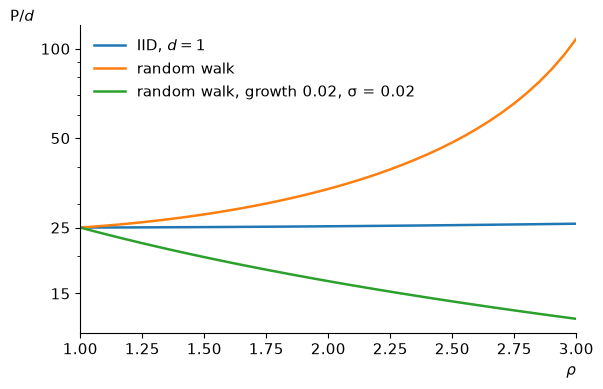

In [ ]:
rho = np.linspace(1, 3, 41)
economies = {
    "IID, $d = 1$": Economy(),
    "random walk": Economy(tau=1),
    "random walk, growth 0.02, σ = 0.02": Economy(tau=1, gamma=0.02, sigma=0.02),
}
lines = {label: [pd_series(replace(et, rho=r), 1) for r in rho] for label, et in economies.items()}
fig, ax = plt.subplots()
lucas.draw_against_rho(ax, rho, lines, log=True)

## A small tree

Lucas's tree is the whole economy. A tree too small to change consumption is priced with the same stochastic discount factor, $\beta(c_{t+1}/c_{t})^{-\rho}$, but has a dividend of its own, $d^{s}$. Suppose the log of its dividend's growth loads $b$ on the economy's shock and has a shock $\omega\eta_{t+1}$ of its own, independent of everything else, with $\eta \sim \mathcal{N}(0,1)$:

$$
\log\left(\frac{d^{s}_{t+1}}{d^{s}_{t}}\right) = \gamma_{s} - \frac{b^{2}\sigma^{2}+\omega^{2}}{2} + b\left(z_{t+1}+\frac{\sigma^{2}}{2}\right) + \omega\eta_{t+1}.
$$

Its dividend is expected to grow by the factor $e^{\gamma_{s}}$ whatever $b$ and $\omega$ are, so raising either makes it riskier without changing its mean. With $b = 1$, $\omega = 0$ and $\gamma_{s} = \gamma$, it is Lucas's tree in a random walk economy.

In a random walk economy the ratio has a closed form, $1/\big((\beta y)^{-1}-1\big)$ with $\log y = \gamma_{s} - \rho\gamma + \rho(\rho+1)\sigma^{2}/2 - \rho b\sigma^{2}$, which is approximately a Gordon formula,

$$
\frac{\mathsf{P}^{s}}{d^{s}} \approx \frac{1}{r + \rho b\sigma^{2} - \gamma_{s}},
$$

where $r = \log \mathsf{R}$ is the log of the riskless return factor and $\rho b\sigma^{2}$, $\rho$ times the covariance of the tree's dividend growth with consumption growth, is its premium. Its own risk $\omega$ appears nowhere: investors bear it only as a small part of a portfolio, in which it washes out. And the ratio does not depend on the level of the dividend, so a tree whose dividends are cut in half, with their growth unchanged, is worth half as much.

In [ ]:
def small_tree(b=1.0, own=0.0, growth_rate=None):
    """A small tree's dividend growth: exposure b to the economy's shock, a shock of its own with
    standard deviation `own`, and expected growth by the factor e**growth_rate (the economy's gamma
    if growth_rate is None)."""

    def growth(e, x, x_next, eta):
        g = e.gamma if growth_rate is None else growth_rate
        shock = x_next - (e.tau * x + e.gamma - e.sigma**2 / 2)  # the economy's shock, mean zero
        return np.exp(g - (b**2 * e.sigma**2 + own**2) / 2 + b * shock + own * eta)

    return growth

The same rise in the risk of the small tree's dividend, made two ways, in an economy like the one with growth above: through its exposure to the economy's shock, which lowers the price, or through a shock of its own, which leaves it unchanged. The effect of the exposure is modest, because consumption growth is smooth; that is the [equity premium puzzle](https://intertemporal-choice.github.io/content/asset-pricing/equitypremiumpuzzle).

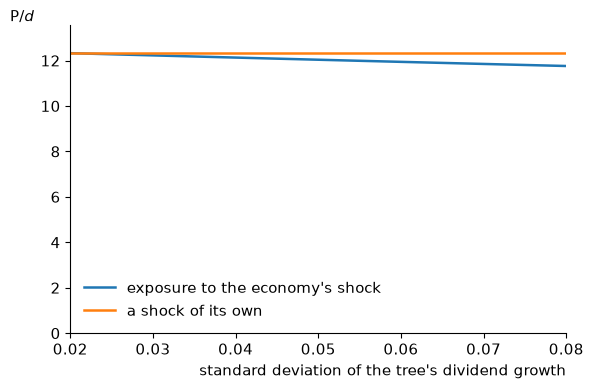

In [ ]:
growing = Economy(tau=1, gamma=0.02, sigma=0.02)
risk = np.linspace(growing.sigma, 4 * growing.sigma, 31)  # the standard deviation of its dividend growth
lines = {
    "exposure to the economy's shock": [solve(growing, small_tree(b=s / growing.sigma))(1) for s in risk],
    "a shock of its own": [solve(growing, small_tree(own=np.sqrt(s**2 - growing.sigma**2)))(1) for s in risk],
}
fig, ax = plt.subplots()
lucas.draw_small_tree(ax, risk, lines, "standard deviation of the tree's dividend growth")

## Using the model in another notebook

The cells that define the model, from the imports through `small_tree`, are also a module of the book's package, `intertemporal_choice.models.lucas`, which the book writes from this notebook, so another notebook, a problem set's answer key say, can compute with exactly this code rather than a copy:

```python
from intertemporal_choice import models

economy = models.lucas.Economy(rho=3, tau=1, gamma=0.02, sigma=0.02)
models.lucas.solve(economy)(1.0)  # the price-dividend ratio at d = 1
```

## The chapter's numbers

These checks stop the book's build if a claim the chapter makes stops matching the computation.

In [ ]:
# Log utility: P/d = 1/theta, whatever the persistence and the dividend.
for tau in (0, 0.9, 1):
    log_utility = replace(e, rho=1, tau=tau)
    assert np.isclose(pd_series(log_utility, 1.7), 1 / e.theta)
    assert np.isclose(solve(log_utility)(1.7), 1 / e.theta, rtol=1e-6)

# IID dividends: P/d = d**(rho-1) e**(rho(rho-1)sigma**2/2) / theta, the chapter's closed form.
for d in (0.5, 1, 2):
    closed = d ** (e.rho - 1) * np.exp(e.rho * (e.rho - 1) * e.sigma**2 / 2) / e.theta
    assert np.isclose(pd_series(e, d), closed) and np.isclose(solve(e)(d), closed, rtol=1e-6)

# 108 for the random walk, 25.8 for IID dividends at d = 1, 25 with no risk; the approximation gives 100.
assert round(pd_series(replace(e, tau=1), 1)) == 108 and round(pd_series(e, 1), 1) == 25.8
assert round(1 / (e.theta - e.rho * (e.rho - 1) * e.sigma**2 / 2)) == 100
# The random walk's price is finite only if beta e**(rho(rho-1)sigma**2/2) < 1: rho = 3.4 fails it.
assert np.isinf(pd_series(replace(e, tau=1, rho=3.4), 1))

# Persistence: 25.8, 26.4, 29.5, 47.6, 80.8 and 108 at d = 1; 103.0, 99.4, 89.3, 73.2 at d = 2, then rising.
taus = (0, 0.6, 0.9, 0.99, 0.999, 1)
assert [round(pd_series(replace(e, tau=t), 1), 1) for t in taus[:-1]] == [25.8, 26.4, 29.5, 47.6, 80.8]
assert [round(pd_series(replace(e, tau=t), 2), 1) for t in taus[:4]] == [103.0, 99.4, 89.3, 73.2]
assert pd_series(replace(e, tau=0.99), 2) < pd_series(replace(e, tau=0.999), 2) < pd_series(replace(e, tau=1), 2)
# ... and the numerical solution matches the series to the chapter's precision.
for t in taus:
    ratio = solve(replace(e, tau=t))
    assert all(np.isclose(ratio(d), pd_series(replace(e, tau=t), d), rtol=1e-3) for d in (1, 2))

# IID dividends: log P = rho log d + a constant, so var(log P) = rho**2 var(log d) ...
slope = np.diff(np.log([d * pd_series(e, d) for d in (0.8, 1.3)])) / np.diff(np.log([0.8, 1.3]))
assert np.isclose(slope, e.rho)
# ... the average price is e**(rho(rho-1)sigma**2)/theta ...
d_draws = np.exp(-e.sigma**2 / 2 + e.sigma * z_std)
prices = np.array([d * pd_series(e, d) for d in d_draws])
assert np.isclose(weights @ prices, np.exp(e.rho * (e.rho - 1) * e.sigma**2) / e.theta)
# ... and a higher rho raises the price at d >= 1 and on average.
for d in (1, 1.5):
    assert pd_series(replace(e, rho=4), d) > pd_series(e, d)

# The riskless rate: log R = log(1+theta) + rho((tau-1)x + gamma) - rho(rho+1)sigma**2/2.
for et in (e, replace(e, tau=0.9), Economy(tau=1, gamma=0.02, sigma=0.02)):
    for d in (0.8, 1, 1.4):
        x = np.log(d)
        log_R = np.log(1 + et.theta) + et.rho * ((et.tau - 1) * x + et.gamma) - et.rho * (et.rho + 1) * et.sigma**2 / 2
        assert np.isclose(np.log(riskless(et, d)), log_R)

# Growth: with gamma = sigma = 0.02 a higher rho lowers the ratio below rho = 50.5 and raises it above;
# the approximation 1/(theta + (rho-1)(gamma - rho sigma**2/2)) is within 5 percent at rho = 3 (12.7 for 12.3).
growing = Economy(tau=1, gamma=0.02, sigma=0.02)
ratios = [pd_series(replace(growing, rho=r), 1) for r in (1, 2, 3, 50, 50.5, 51, 52)]
assert ratios[0] > ratios[1] > ratios[2] > ratios[3] > ratios[4] and ratios[4] < ratios[5] < ratios[6]
approx = 1 / (growing.theta + (growing.rho - 1) * (growing.gamma - growing.rho * growing.sigma**2 / 2))
assert np.isclose(pd_series(growing, 1), approx, rtol=0.05)

# The small tree: Lucas's tree when b = 1 and omega = 0; the closed form; its own risk changes nothing;
# exposure lowers the price.
for et in (replace(e, tau=1), growing):
    assert np.isclose(solve(et, small_tree())(1), pd_series(et, 1), rtol=1e-6)
    for b, own, g in ((1, 0, None), (3, 0, None), (3, 0.2, 0.01), (2, 0.1, -0.01)):
        g_s = et.gamma if g is None else g
        y = et.beta * np.exp(g_s - et.rho * et.gamma + et.rho * (et.rho + 1) * et.sigma**2 / 2 - et.rho * b * et.sigma**2)
        assert np.isclose(solve(et, small_tree(b, own, g))(1), y / (1 - y), rtol=1e-6)
assert np.isclose(solve(growing, small_tree(own=0.3))(1), solve(growing, small_tree())(1), rtol=1e-9)
assert solve(growing, small_tree(b=3))(1) < solve(growing, small_tree())(1)